# 01. Classifying underwater animals with Brackish

**Goal:** learn how to judge a vision model before trusting one. We start with image classification, the simplest task: given a cropped picture of one animal, which class is it?

**The path:** data, then classification, then detection, then video. This notebook is the first two steps.

**What you'll learn:**
1. Why train, validation and test sets are separate
2. How to split data without leaking answers
3. How transfer learning works
4. How to read a confusion matrix
5. Why a published score can mislead

Run the cells in order with Shift+Enter. Downloading and preparing data takes about 2 minutes, and each training run takes about 8 minutes on an Apple GPU.

## 1. Setup

These are the settings you can change. Lower `EPOCHS` or `PER_CLASS` for a quick try.

In [1]:
import collections
import json
import random
import re
import shutil
import time
import urllib.request
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pyarrow.parquet as pq
import torch
from IPython.display import display
from torch import nn
from torch.utils.data import DataLoader, Subset, WeightedRandomSampler
from torchvision import datasets, models, transforms
from tqdm.auto import tqdm

EPOCHS = 6  # full passes over the training data
PER_CLASS = 3000  # cap on training crops per class, to keep runs short
BATCH_SIZE = 48
SEED = 42

ROOT = Path.cwd()
while not (ROOT / "server").exists():
    ROOT = ROOT.parent
PARQUET = ROOT / "data" / "datasets" / "brackish-parquet"
CROPS = ROOT / "data" / "datasets" / "brackish-crops"
CLASSES = ["crab", "fish", "jellyfish", "shrimp", "small_fish", "starfish"]
COLORS = dict(zip(CLASSES, ["#e4572e", "#1f5eff", "#17b890", "#f3a712", "#a855f7", "#111827"]))
DEVICE = "mps" if torch.backends.mps.is_available() else "cpu"

random.seed(SEED)
torch.manual_seed(SEED)
print("Running on", DEVICE)

Running on mps


## 2. Get the data

**Brackish** comes from a camera fixed 9 m underwater on a bridge in Denmark. It has 6 classes and comes from 89 videos, so it's useful for images now and video later.

This mirror has about 12,000 frames that contain animals. Each box is `[x_min, y_min, x_max, y_max]`, scaled from 0 to 1.

In [4]:
BASE = "https://huggingface.co/datasets/moondream/brackish_underwater/resolve/main/data"
PARQUET.mkdir(parents=True, exist_ok=True)


def download(url, path):
    with urllib.request.urlopen(url) as response, open(path, "wb") as file:
        with tqdm.wrapattr(file, "write", total=response.length, desc=path.name) as output:
            shutil.copyfileobj(response, output)


for split in ("train", "valid", "test"):
    path = PARQUET / f"{split}.parquet"
    if not path.exists():
        download(f"{BASE}/{split}-00000-of-00001.parquet", path)

frames = []
for split in ("train", "valid", "test"):
    for batch in tqdm(pq.ParquetFile(PARQUET / f"{split}.parquet").iter_batches(batch_size=64), desc=split):
        for row in batch.to_pylist():
            match = re.match(r"(.+)-(\d{4})_jpg", row["image"]["path"])
            frames.append({
                "video": match.group(1),
                "frame": int(match.group(2)),
                "original_split": split,
                "bytes": row["image"]["bytes"],
                "boxes": [(o["name"], *box) for o in row["objects"] for box in o["boxes"]],
            })

print(len(frames), "frames from", len({f["video"] for f in frames}), "videos")

train: 0it [00:00, ?it/s]

valid: 0it [00:00, ?it/s]

test: 0it [00:00, ?it/s]

12444 frames from 89 videos


## 3. Look at the data first

Always look before modelling. Notice how small the animals are, and how poor the visibility is.

frames:   0%|          | 0/6 [00:00<?, ?it/s]

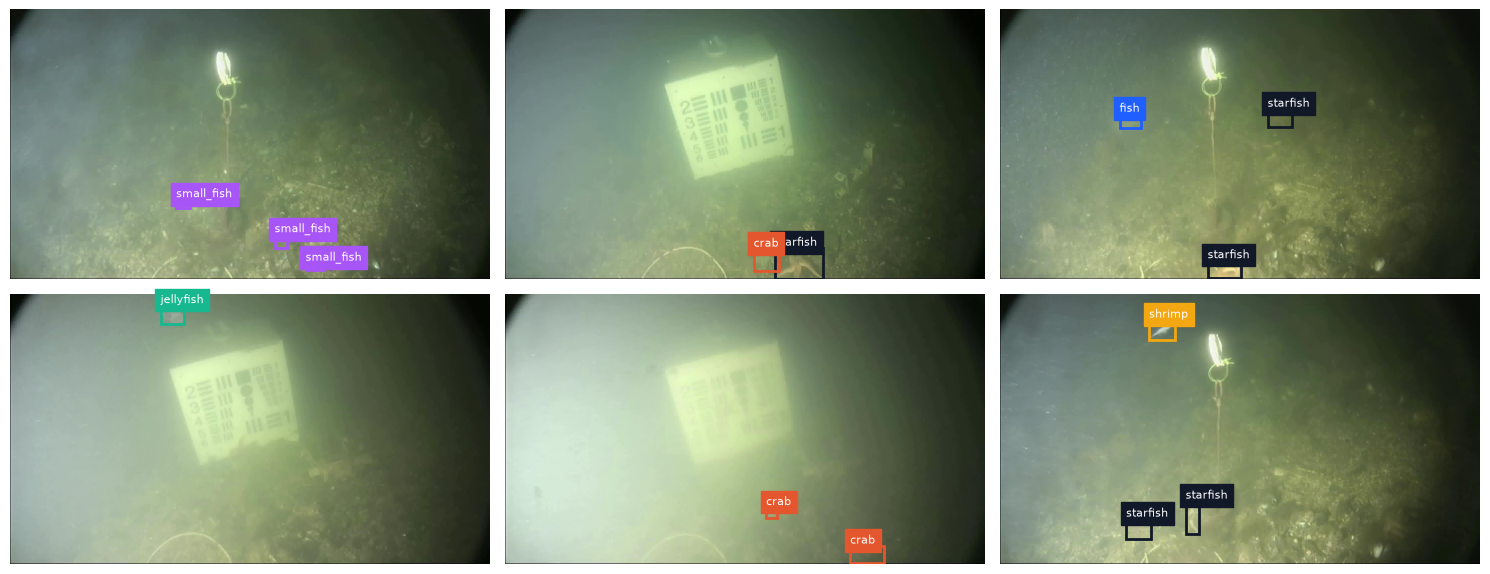

In [5]:
def decode(frame):
    return cv2.cvtColor(cv2.imdecode(np.frombuffer(frame["bytes"], np.uint8), cv2.IMREAD_COLOR), cv2.COLOR_BGR2RGB)


def show_frame(ax, frame):
    image = decode(frame)
    height, width = image.shape[:2]
    ax.imshow(image)
    for name, x1, y1, x2, y2 in frame["boxes"]:
        ax.add_patch(plt.Rectangle((x1 * width, y1 * height), (x2 - x1) * width, (y2 - y1) * height,
                                   fill=False, edgecolor=COLORS[name], linewidth=2))
        ax.text(x1 * width, y1 * height - 8, name, color="white", fontsize=8, backgroundcolor=COLORS[name])
    ax.axis("off")


fig, axes = plt.subplots(2, 3, figsize=(15, 6))
for frame, ax in zip(tqdm(random.sample(frames, 6), desc="frames"), axes.flat):
    show_frame(ax, frame)
plt.tight_layout()
plt.show()

**Class balance.** Look at how uneven these bars are. If a model ignored shrimp completely, overall accuracy would barely drop. That's why we'll use a metric that treats every class equally.

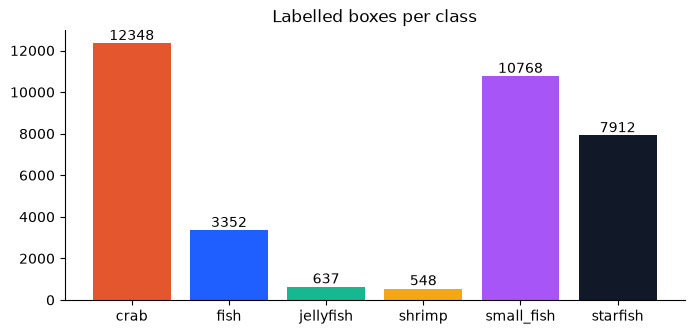

In [6]:
boxes_per_class = collections.Counter(box[0] for f in frames for box in f["boxes"])
fig, ax = plt.subplots(figsize=(8, 3.5))
bars = ax.bar(CLASSES, [boxes_per_class[c] for c in CLASSES], color=[COLORS[c] for c in CLASSES])
ax.bar_label(bars)
ax.set_title("Labelled boxes per class")
ax.spines[["top", "right"]].set_visible(False)
plt.show()

## 4. Check for leakage

A model should be tested on things it hasn't seen. Neighbouring video frames look almost identical, so if one video's frames land in both train and test, the test is partly a memory check.

**The check:** in the dataset's published split, how many videos appear in more than one split?

89 of 89 videos appear in more than one published split


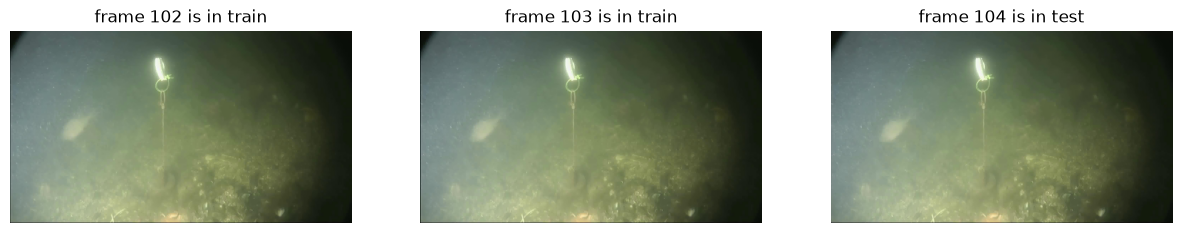

In [7]:
splits_per_video = collections.defaultdict(set)
for frame in frames:
    splits_per_video[frame["video"]].add(frame["original_split"])

leaking = sum(1 for s in splits_per_video.values() if len(s) > 1)
print(f"{leaking} of {len(splits_per_video)} videos appear in more than one published split")

video = next(iter(splits_per_video))
same_video = sorted((f for f in frames if f["video"] == video), key=lambda f: f["frame"])
middle = len(same_video) // 2
fig, axes = plt.subplots(1, 3, figsize=(15, 3))
for ax, frame in zip(axes, same_video[middle:middle + 3]):
    ax.imshow(decode(frame))
    ax.set_title(f"frame {frame['frame']} is in {frame['original_split']}")
    ax.axis("off")
plt.show()

## 5. Split by video

Three sets, three jobs:

| Set | Job |
|---|---|
| **Train** | The model learns from it |
| **Validation** | We use it to choose settings and the best epoch |
| **Test** | We read it once at the end, to estimate real performance |

We keep whole videos together. This code places rare-class videos first, so that each set gets some of every class.

In [8]:
SHARES = {"train": 0.70, "val": 0.15, "test": 0.15}


def split_by_video(frames):
    per_video = collections.defaultdict(collections.Counter)
    for frame in frames:
        per_video[frame["video"]].update(box[0] for box in frame["boxes"])
    totals = collections.Counter()
    for counts in per_video.values():
        totals.update(counts)
    rarity = {c: 1 / totals[c] for c in CLASSES}

    videos = list(per_video)
    random.Random(SEED).shuffle(videos)
    videos.sort(key=lambda v: -sum(rarity[c] * n for c, n in per_video[v].items()))

    filled = {s: collections.Counter() for s in SHARES}
    assigned = {}
    for video in videos:
        def need(split):
            return sum(rarity[c] * n * (SHARES[split] * totals[c] - filled[split][c]) for c, n in per_video[video].items())
        best = max(SHARES, key=need)
        assigned[video] = best
        filled[best].update(per_video[video])
    return assigned


video_split = split_by_video(frames)
print(collections.Counter(video_split.values()))

Counter({'train': 44, 'val': 23, 'test': 22})


**From detection labels to classification data.** Each labelled box becomes one cropped image, with a little padding for context. Boxes under 12 pixels are skipped, because they hold too little to classify.

We also build a second copy that splits **randomly by frame**. It's deliberately wrong, so we can measure the leak later.

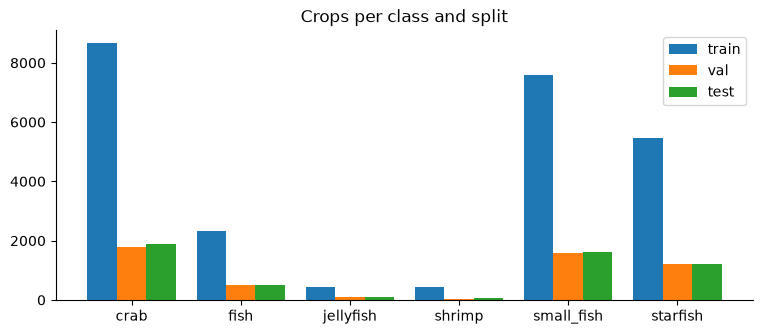

In [9]:
PADDING = 0.15
MIN_SIDE = 12


def write_crops(frames, layout, choose_split):
    for frame in tqdm(frames, desc=layout):
        split = choose_split(frame)
        image = cv2.imdecode(np.frombuffer(frame["bytes"], np.uint8), cv2.IMREAD_COLOR)
        height, width = image.shape[:2]
        for n, (name, x_min, y_min, x_max, y_max) in enumerate(frame["boxes"]):
            box_w, box_h = (x_max - x_min) * width, (y_max - y_min) * height
            if min(box_w, box_h) < MIN_SIDE:
                continue
            x1 = max(0, int(x_min * width - box_w * PADDING))
            y1 = max(0, int(y_min * height - box_h * PADDING))
            x2 = min(width, int(x_max * width + box_w * PADDING))
            y2 = min(height, int(y_max * height + box_h * PADDING))
            folder = CROPS / layout / split / name
            folder.mkdir(parents=True, exist_ok=True)
            cv2.imwrite(str(folder / f"{frame['video']}-{frame['frame']:04d}-{n}.jpg"), image[y1:y2, x1:x2])


if not (CROPS / "by_video").exists():
    write_crops(frames, "by_video", lambda f: video_split[f["video"]])
if not (CROPS / "random_frames").exists():
    rng = random.Random(SEED)
    frame_roll = {(f["video"], f["frame"]): rng.random() for f in frames}

    def by_frame(frame):
        roll = frame_roll[(frame["video"], frame["frame"])]
        return "train" if roll < 0.7 else "val" if roll < 0.85 else "test"

    write_crops(frames, "random_frames", by_frame)


def counts(layout):
    return {s: {c: len(list((CROPS / layout / s / c).glob("*.jpg"))) for c in CLASSES} for s in SHARES}


table = counts("by_video")
fig, ax = plt.subplots(figsize=(9, 3.5))
x = np.arange(len(CLASSES))
for i, split in enumerate(SHARES):
    ax.bar(x + (i - 1) * 0.27, [table[split][c] for c in CLASSES], 0.27, label=split)
ax.set_xticks(x, CLASSES)
ax.set_title("Crops per class and split")
ax.legend()
ax.spines[["top", "right"]].set_visible(False)
plt.show()

**Look at what the model will see.** Could you tell `fish` from `small_fish`? Shrimp from a smudge? If you can't, the model probably can't either.

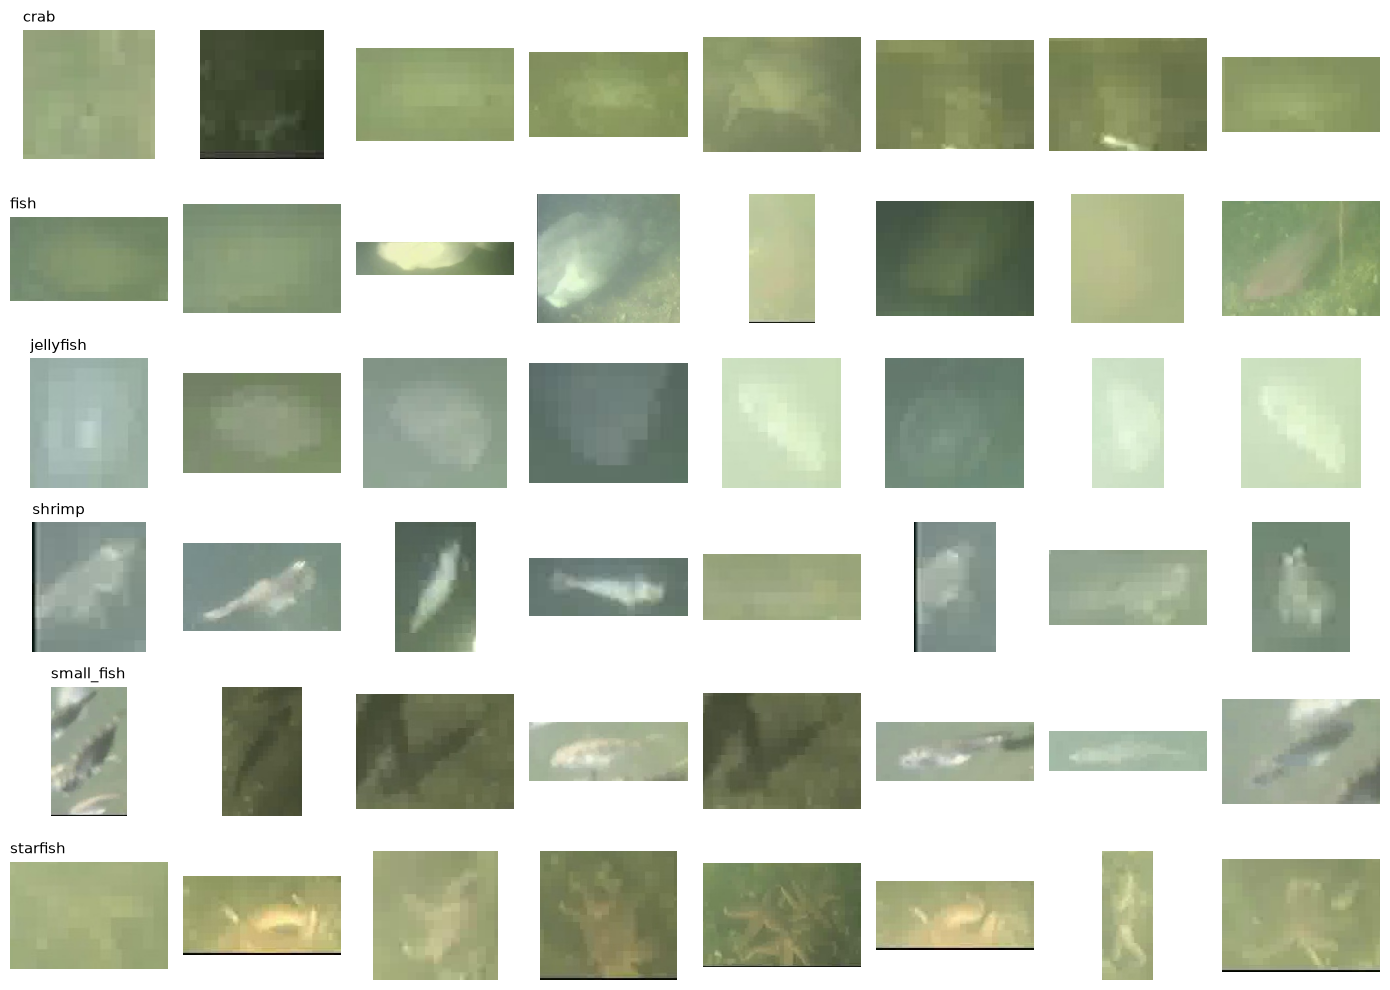

In [10]:
fig, axes = plt.subplots(len(CLASSES), 8, figsize=(14, 10))
for row, name in zip(axes, CLASSES):
    files = random.sample(sorted((CROPS / "by_video" / "train" / name).glob("*.jpg")), 8)
    for ax, path in zip(row, files):
        ax.imshow(cv2.cvtColor(cv2.imread(str(path)), cv2.COLOR_BGR2RGB))
        ax.axis("off")
    row[0].set_title(name, loc="left", fontsize=11)
plt.tight_layout()
plt.show()

## 6. Prepare images for the model

- **Resize:** every crop becomes 224×224.
- **Normalize:** we use the same colour scaling the pretrained network was trained with.
- **Augment:** random flips and colour changes, on training data only. They help the model not memorize exact pictures.
- **Balanced sampling:** rare classes are shown as often as common ones.

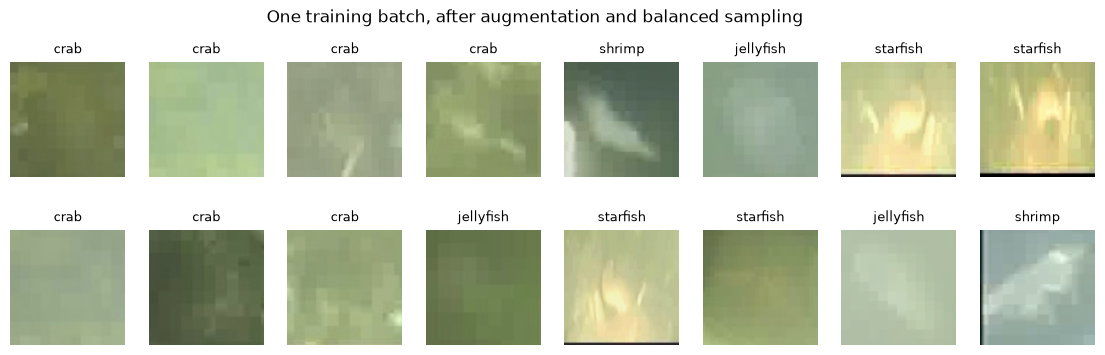

In [ ]:
SIZE = 224
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]

train_transform = transforms.Compose([
    transforms.Resize((SIZE, SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.ColorJitter(0.2, 0.2, 0.2),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])
eval_transform = transforms.Compose([
    transforms.Resize((SIZE, SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])


def capped(dataset, limit):
    rng = random.Random(SEED)
    by_class = collections.defaultdict(list)
    for index, label in enumerate(dataset.targets):
        by_class[label].append(index)
    keep = []
    for rows in by_class.values():
        rng.shuffle(rows)
        keep.extend(rows[:limit])
    return Subset(dataset, keep), [dataset.targets[i] for i in keep]


def make_loaders(layout):
    root = CROPS / layout
    train_all = datasets.ImageFolder(root / "train", train_transform)
    val_all = datasets.ImageFolder(root / "val", eval_transform)
    test_all = datasets.ImageFolder(root / "test", eval_transform)
    train_set, targets = capped(train_all, PER_CLASS)
    val_set, _ = capped(val_all, 1000)
    class_counts = np.bincount(targets, minlength=len(CLASSES))
    sampler = WeightedRandomSampler(
        [1 / class_counts[t] for t in targets], len(targets), generator=torch.Generator().manual_seed(SEED)
    )
    return {
        "train": DataLoader(train_set, batch_size=BATCH_SIZE, sampler=sampler, num_workers=2),
        "val": DataLoader(val_set, batch_size=96, num_workers=2),
        "test": DataLoader(test_all, batch_size=96, num_workers=2),
        "test_set": test_all,
    }


loaders = make_loaders("by_video")
images, labels = next(iter(loaders["train"]))
fig, axes = plt.subplots(2, 8, figsize=(14, 4))
for ax, image, label in zip(axes.flat, images, labels):
    picture = (image.permute(1, 2, 0).numpy() * STD + MEAN).clip(0, 1)
    ax.imshow(picture)
    ax.set_title(CLASSES[label], fontsize=9)
    ax.axis("off")
plt.suptitle("One training batch, after augmentation and balanced sampling")
plt.show()

## 7. The model: transfer learning

**ResNet18** is a convolutional neural network. Early layers learn edges and textures, and later layers learn shapes and objects. Its starting weights were trained on ImageNet, 1.2 million everyday photos.

Instead of learning from zero, we:
1. Replace the last layer with one that outputs our 6 classes
2. Freeze the early layers, because edges are edges everywhere
3. Train only the later layers on underwater images

In [12]:
def make_model():
    model = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)
    model.fc = nn.Linear(model.fc.in_features, len(CLASSES))
    for name, parameter in model.named_parameters():
        parameter.requires_grad = name.startswith(("layer3", "layer4", "fc"))
    return model.to(DEVICE)


model = make_model()
total = sum(p.numel() for p in model.parameters())
trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"{trainable:,} of {total:,} parameters will train")
del model

10,496,518 of 11,179,590 parameters will train


## 8. How we score

**Accuracy** is the share of correct answers. It can hide a class the model never gets right.

For each class:
- **Recall:** of the real shrimp, how many did we find?
- **Precision:** of the things we called shrimp, how many really were?
- **F1:** a single score that combines the two

**Macro F1** averages F1 across classes, so shrimp counts as much as crab. This is the score we use to pick the best epoch.

In [13]:
def metrics(matrix):
    recall = matrix.diagonal() / np.maximum(matrix.sum(1), 1)
    precision = matrix.diagonal() / np.maximum(matrix.sum(0), 1)
    f1 = 2 * precision * recall / np.maximum(precision + recall, 1e-9)
    return {
        "accuracy": matrix.diagonal().sum() / matrix.sum(),
        "macro_f1": f1.mean(),
        "recall": recall,
        "precision": precision,
        "f1": f1,
    }


@torch.no_grad()
def predict(model, loader):
    model.eval()
    truth, guesses = [], []
    for images, labels in tqdm(loader, desc="predict", leave=False):
        guesses.append(model(images.to(DEVICE)).argmax(1).cpu().numpy())
        truth.append(labels.numpy())
    return np.concatenate(truth), np.concatenate(guesses)


def confusion(truth, guesses):
    matrix = np.zeros((len(CLASSES), len(CLASSES)), dtype=int)
    np.add.at(matrix, (truth, guesses), 1)
    return matrix

## 9. Train

Each step: show the model a batch, measure its mistakes (the **loss**), then nudge its weights to reduce them.

The chart updates after every epoch:
- **Left:** training loss should fall.
- **Middle:** macro F1 on validation footage the model hasn't trained on.
- **Right:** validation F1 per class, which shows which classes struggle.

**What to watch:** if training loss keeps falling but validation stops improving, the model is **overfitting**: it's memorizing training videos instead of learning general rules. We keep the epoch with the best validation score, not the last one.

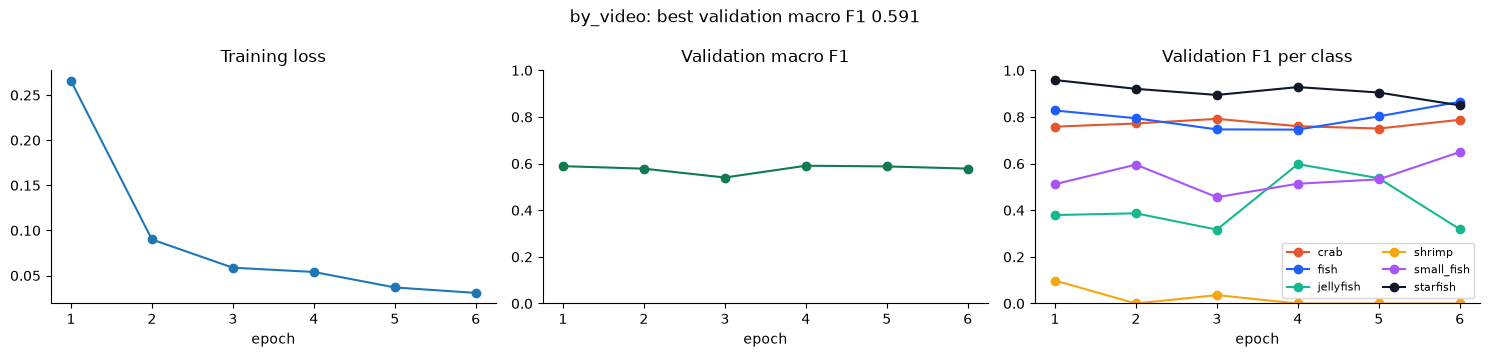

epoch 1/6:   0%|          | 0/255 [00:03<?, ?it/s]

predict:   0%|          | 0/39 [00:02<?, ?it/s]

epoch 2/6:   0%|          | 0/255 [00:03<?, ?it/s]

predict:   0%|          | 0/39 [00:01<?, ?it/s]

epoch 3/6:   0%|          | 0/255 [00:03<?, ?it/s]

predict:   0%|          | 0/39 [00:04<?, ?it/s]

... (2 outputs left out)

epoch 5/6:   0%|          | 0/255 [00:03<?, ?it/s]

predict:   0%|          | 0/39 [00:02<?, ?it/s]

epoch 6/6:   0%|          | 0/255 [00:03<?, ?it/s]

predict:   0%|          | 0/39 [00:02<?, ?it/s]

In [14]:
def plot_progress(history, title):
    fig, axes = plt.subplots(1, 3, figsize=(15, 3.6))
    epochs = [h["epoch"] for h in history]
    axes[0].plot(epochs, [h["loss"] for h in history], marker="o")
    axes[0].set_title("Training loss")
    axes[1].plot(epochs, [h["macro_f1"] for h in history], marker="o", color="#0f7b4f")
    axes[1].set_ylim(0, 1)
    axes[1].set_title("Validation macro F1")
    for i, name in enumerate(CLASSES):
        axes[2].plot(epochs, [h["f1"][i] for h in history], marker="o", label=name, color=COLORS[name])
    axes[2].set_ylim(0, 1)
    axes[2].set_title("Validation F1 per class")
    axes[2].legend(fontsize=8, ncol=2)
    for ax in axes:
        ax.set_xlabel("epoch")
        ax.spines[["top", "right"]].set_visible(False)
    fig.suptitle(title)
    fig.tight_layout()
    return fig


def train(layout):
    torch.manual_seed(SEED)
    loaders = make_loaders(layout)
    model = make_model()
    optimizer = torch.optim.AdamW([p for p in model.parameters() if p.requires_grad], lr=3e-4, weight_decay=1e-4)
    loss_fn = nn.CrossEntropyLoss()
    history, best_score, best_state = [], -1.0, None
    chart = display(plt.figure(), display_id=True)
    plt.close("all")

    for epoch in range(1, EPOCHS + 1):
        model.train()
        running, seen = 0.0, 0
        bar = tqdm(loaders["train"], desc=f"epoch {epoch}/{EPOCHS}", leave=False)
        for images, labels in bar:
            optimizer.zero_grad()
            loss = loss_fn(model(images.to(DEVICE)), labels.to(DEVICE))
            loss.backward()
            optimizer.step()
            running += loss.item() * len(labels)
            seen += len(labels)
            bar.set_postfix(loss=f"{running / seen:.3f}")

        val = metrics(confusion(*predict(model, loaders["val"])))
        history.append({"epoch": epoch, "loss": running / seen, "macro_f1": val["macro_f1"], "f1": val["f1"]})
        if val["macro_f1"] > best_score:
            best_score = val["macro_f1"]
            best_state = {k: v.cpu().clone() for k, v in model.state_dict().items()}
        figure = plot_progress(history, f"{layout}: best validation macro F1 {best_score:.3f}")
        chart.update(figure)
        plt.close(figure)

    model.load_state_dict(best_state)
    return model, loaders, history


model, loaders, history = train("by_video")

## 10. Read the test set once

This is our estimate of how the model does on videos it never saw.

**How to read a confusion matrix:** each row is the true class, and each column is what the model said. The diagonal is correct. Everything else is a specific kind of mistake, which tells you what to fix.

predict:   0%|          | 0/57 [00:01<?, ?it/s]

Accuracy 0.856   Macro F1 0.678

class         crops   recall  precision     F1
crab           1894     0.88       0.86   0.87
fish            517     0.92       0.74   0.82
jellyfish       105     0.92       0.44   0.60
shrimp           56     0.00       0.00   0.00
small_fish     1614     0.81       0.89   0.85
starfish       1216     0.89       0.98   0.93


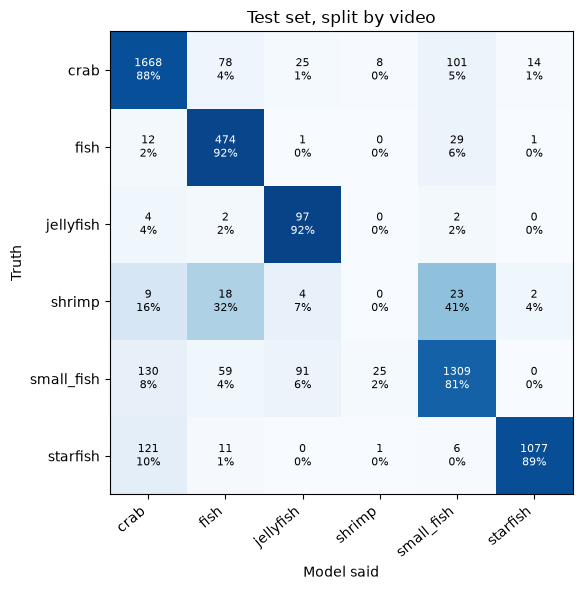

In [15]:
def plot_confusion(matrix, title):
    shares = matrix / np.maximum(matrix.sum(1, keepdims=True), 1)
    fig, ax = plt.subplots(figsize=(7, 6))
    ax.imshow(shares, cmap="Blues", vmin=0, vmax=1)
    ax.set_xticks(range(len(CLASSES)), CLASSES, rotation=40, ha="right")
    ax.set_yticks(range(len(CLASSES)), CLASSES)
    ax.set_xlabel("Model said")
    ax.set_ylabel("Truth")
    ax.set_title(title)
    for row in range(len(CLASSES)):
        for col in range(len(CLASSES)):
            ax.text(col, row, f"{matrix[row, col]}\n{shares[row, col]:.0%}", ha="center", va="center",
                    fontsize=8, color="white" if shares[row, col] > 0.5 else "black")
    fig.tight_layout()
    plt.show()


def report(matrix):
    result = metrics(matrix)
    print(f"Accuracy {result['accuracy']:.3f}   Macro F1 {result['macro_f1']:.3f}\n")
    print(f"{'class':12s}{'crops':>7s}{'recall':>9s}{'precision':>11s}{'F1':>7s}")
    for i, name in enumerate(CLASSES):
        print(f"{name:12s}{matrix[i].sum():7d}{result['recall'][i]:9.2f}{result['precision'][i]:11.2f}{result['f1'][i]:7.2f}")
    return result


truth, guesses = predict(model, loaders["test"])
matrix = confusion(truth, guesses)
video_result = report(matrix)
plot_confusion(matrix, "Test set, split by video")

**Look at the mistakes.** Numbers say how often the model fails, and pictures show why. Some labels may be wrong, and some crops may be impossible even for a person.

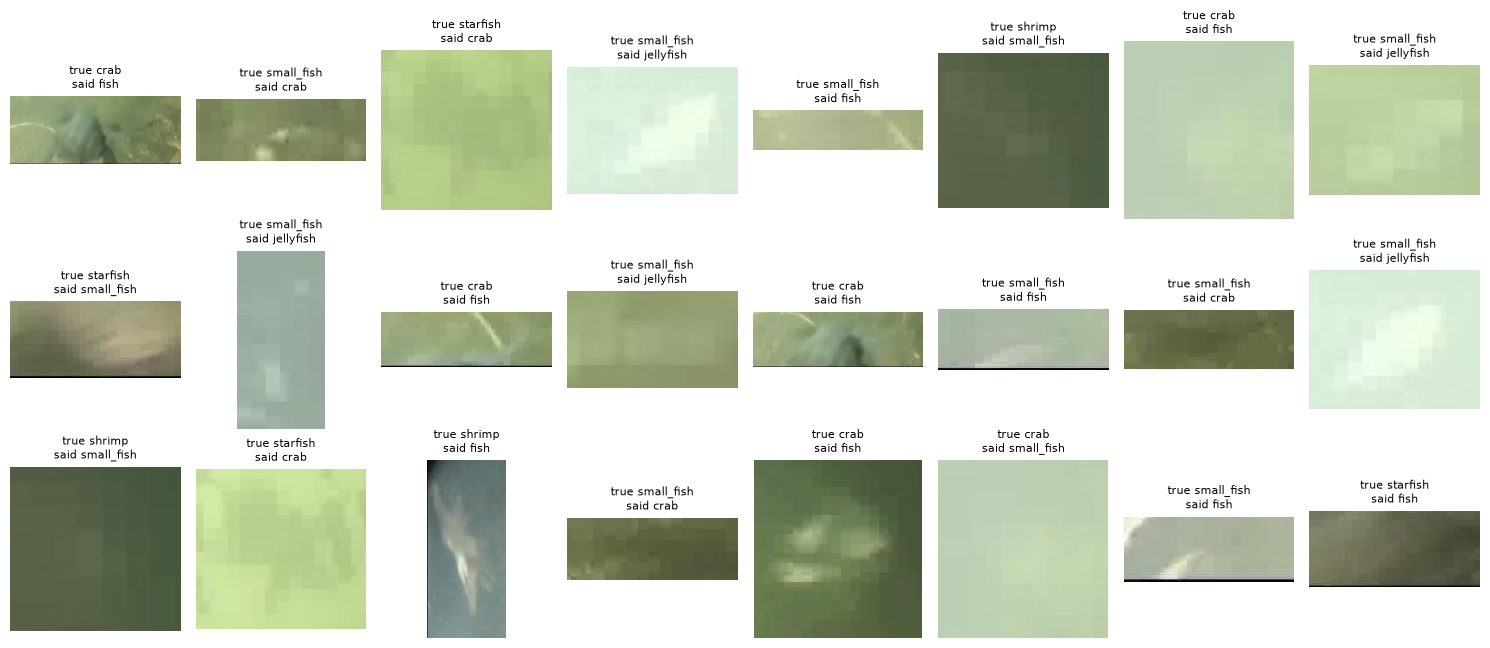

In [16]:
wrong = np.flatnonzero(truth != guesses)
picks = np.random.default_rng(SEED).choice(wrong, size=min(24, len(wrong)), replace=False)
paths = [path for path, _ in loaders["test_set"].samples]
fig, axes = plt.subplots(3, 8, figsize=(15, 6.5))
for ax, i in zip(axes.flat, picks):
    ax.imshow(cv2.cvtColor(cv2.imread(paths[i]), cv2.COLOR_BGR2RGB))
    ax.set_title(f"true {CLASSES[truth[i]]}\nsaid {CLASSES[guesses[i]]}", fontsize=8)
    ax.axis("off")
plt.tight_layout()
plt.show()

## 11. Experiment: how much does leakage inflate the score?

Same model and same settings. The only change is that frames are split at random, so test frames have near-copies in training.

If this score is higher, that gap is **not** real skill. It's the model recognizing footage it has seen.

In [ ]:
leaky_model, leaky_loaders, leaky_history = train("random_frames")
leaky_matrix = confusion(*predict(leaky_model, leaky_loaders["test"]))
leaky_result = report(leaky_matrix)

<Figure size 640x480 with 0 Axes>

epoch 1/6:   0%|          | 0/254 [00:03<?, ?it/s]

predict:   0%|          | 0/39 [00:01<?, ?it/s]

## 12. Baseline: BioCLIP with no training

A trained model should beat a free option. BioCLIP is the model TideCount uses now. Here it only gets the class names, and it's scored on up to 300 test crops per class.

In [ ]:
import open_clip
from PIL import Image

clip_model, _, clip_preprocess = open_clip.create_model_and_transforms("hf-hub:imageomics/bioclip")
tokenizer = open_clip.get_tokenizer("hf-hub:imageomics/bioclip")
clip_model = clip_model.to(DEVICE).eval()
prompts = {
    "crab": "a photo of a crab", "fish": "a photo of a large fish", "jellyfish": "a photo of a jellyfish",
    "shrimp": "a photo of a shrimp", "small_fish": "a photo of a small fish", "starfish": "a photo of a starfish",
}
with torch.no_grad():
    text = clip_model.encode_text(tokenizer([prompts[c] for c in CLASSES]).to(DEVICE))
    text = text / text.norm(dim=-1, keepdim=True)

clip_matrix = np.zeros((len(CLASSES), len(CLASSES)), dtype=int)
rng = random.Random(SEED)
for row, name in enumerate(CLASSES):
    files = sorted((CROPS / "by_video" / "test" / name).glob("*.jpg"))
    rng.shuffle(files)
    for path in tqdm(files[:300], desc=name):
        with torch.no_grad():
            image = clip_model.encode_image(clip_preprocess(Image.open(path).convert("RGB"))[None].to(DEVICE))
            image = image / image.norm(dim=-1, keepdim=True)
            clip_matrix[row, int((image @ text.T).argmax())] += 1

clip_result = report(clip_matrix)
plot_confusion(clip_matrix, "BioCLIP, no training")

## 13. Compare

For scores like these, the honest bar is the first one.

In [ ]:
runs = {
    "ResNet18\nsplit by video": video_result,
    "ResNet18\nleaky frames": leaky_result,
    "BioCLIP\nno training": clip_result,
}
fig, ax = plt.subplots(figsize=(8, 4))
x = np.arange(len(runs))
accuracy = ax.bar(x - 0.2, [r["accuracy"] for r in runs.values()], 0.4, label="Accuracy")
macro = ax.bar(x + 0.2, [r["macro_f1"] for r in runs.values()], 0.4, label="Macro F1")
ax.bar_label(accuracy, fmt="%.2f")
ax.bar_label(macro, fmt="%.2f")
ax.set_xticks(x, list(runs))
ax.set_ylim(0, 1.1)
ax.legend()
ax.spines[["top", "right"]].set_visible(False)
plt.show()

## 14. What to take away

Answer these from your own charts:

1. Which class is worst, and is the cause too few examples, tiny crops, or confusing labels?
2. Which two classes get mixed up most? Could a person tell them apart?
3. How far apart are the split-by-video and leaky scores? What does that say about published results?
4. Did training loss keep falling after validation stopped improving?

**Remember the limit:** these animals and water are from Denmark, so this doesn't tell us how the model does in Nova Scotia. It teaches the method.

**Next:** `02` moves from classification to detection, where the model must also find the animal in the full frame.